# Examen Parcial II · Problema 2: Compra Fácil Bajío
**Equipo:** Emilio Frausto, Juan, Rodrigo Rosales (cuaderno DEV)

**El cliente:** una tienda en línea que quiere detectar las reseñas negativas (1 o 2 estrellas) para que atención a clientes conteste primero a quien está molesto.

**Lo que pide, en la prueba y con umbral de 0.5:**
- Exhaustividad de 90 % o más: de cada 100 reseñas negativas, que marque al menos 90.
- Precisión de 85 % o más: de cada 100 que marque como negativas, que al menos 85 lo sean.
- El modelo tiene que ser nuestro, entrenado por nosotros. Un LLM por API no cuenta.

**Cómo lo hacemos:** una línea base trivial, Bigramas, Embedding + Bi-LSTM y BETO ajustado. Todo lo decidimos con validación y la prueba la usamos una sola vez al final.
Como extra entrenamos un Bi-LSTM con las 5 estrellas, para ver si saber la calificación completa le da más contexto. Ese mismo modelo es el que usa la app de Gradio para recomendar cuántas estrellas poner.

### Importaciones

In [1]:
import os
import importlib.util

en_colab = importlib.util.find_spec("google.colab") is not None
os.environ["KERAS_BACKEND"] = "tensorflow" if en_colab else "torch"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["USE_TF"] = "0"  # que transformers use pytorch
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

import json
import time
import keras
import tensorflow as tf  # TextVectorization y tf.data lo necesitan
import torch
import transformers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras import layers
from sklearn.metrics import accuracy_score, recall_score, precision_score, ConfusionMatrixDisplay

SEED = 42
keras.utils.set_random_seed(SEED)
transformers.set_seed(SEED)
pd.set_option("display.max_colwidth", 200)
GPU = torch.cuda.is_available()
print("Backend:", keras.backend.backend())
print("GPU:", torch.cuda.get_device_name(0) if GPU else "no hay")

Backend: torch
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Datos
Usamos exactamente la carga y la prueba que pide el examen.

In [2]:
URL = "https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es/resolve/main/{}.jsonl"
partes = {p: pd.read_json(URL.format(p), lines=True) for p in ["train", "validation", "test"]}
for df in partes.values():
    df["estrellas"] = df["label"] + 1                 # label va de 0 a 4
train, val, test = partes["train"], partes["validation"], partes["test"]
# Prueba del cliente: la partición test sin las de 3 estrellas (4,000 reseñas, mitad negativas).
# 1 = negativa. No la toquen hasta el final.
prueba = test[test["estrellas"] != 3]
X_prueba, y_prueba = prueba["text"].values, (prueba["estrellas"] <= 2).astype(int).values

### Tamaño y balance

In [3]:
print(f"Entrenamiento: {len(train):,} · Validación: {len(val):,} · Test: {len(test):,} · Prueba del cliente: {len(prueba):,}")

conteo = pd.DataFrame({"Entrenamiento": train["estrellas"].value_counts(),
                       "Validación": val["estrellas"].value_counts(),
                       "Test": test["estrellas"].value_counts()}).sort_index()
conteo

Entrenamiento: 200,000 · Validación: 5,000 · Test: 5,000 · Prueba del cliente: 4,000


,Entrenamiento,Validación,Test
estrellas,,,
1,40000,1000,1000
2,40000,1000,1000
3,40000,1000,1000
4,40000,1000,1000
5,40000,1000,1000


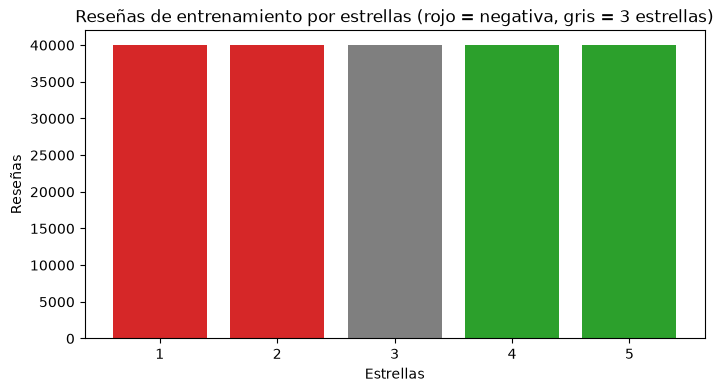

In [4]:
# Gráfica 1: cuántas reseñas hay de cada estrella en entrenamiento
colores = ["tab:red", "tab:red", "tab:gray", "tab:green", "tab:green"]
plt.figure(figsize=(8, 4))
plt.bar(conteo.index, conteo["Entrenamiento"], color=colores)
plt.title("Reseñas de entrenamiento por estrellas (rojo = negativa, gris = 3 estrellas)")
plt.xlabel("Estrellas")
plt.ylabel("Reseñas")
plt.show()

In [5]:
# Ejemplos: una reseña de cada estrella
train.groupby("estrellas").head(1)[["estrellas", "text"]].sort_values("estrellas")

,estrellas,text
0,1,Nada bueno se me fue ka pantalla en menos de 8 meses y no he recibido respuesta del fabricante
40000,2,"Los tornillos no ajustan bien, se caen. No lo volvería a comprar"
80000,3,"cabe bien un móvil de 5,5 y cumple su función se hecha de menos un pequeño espacio para guardar tarjeta o efectivo seria muy útil"
120000,4,"Tiene buena pinta, veremos el resultado"
160000,5,"Es muy práctico para cuando me voy de vacaciones, ya no me tengo que preocupar de si seguirán vivas las plantas cuando vuelva. El montaje es muy sencillo y se puede regular la salida de agua para ..."


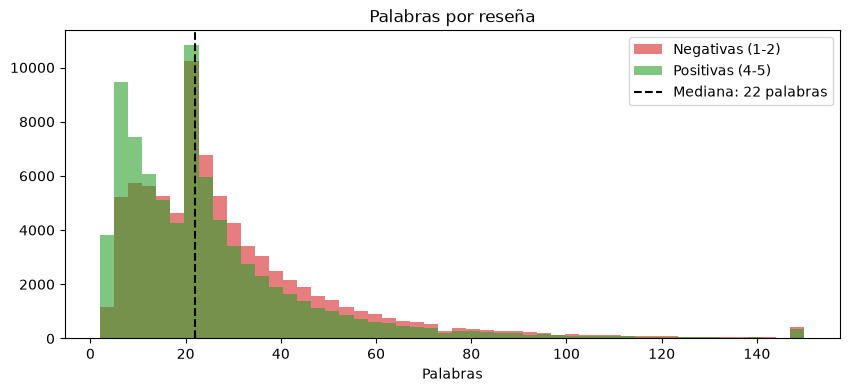

Mediana de palabras · negativas: 23 · positivas: 20


In [6]:
# Gráfica 2: palabras por reseña, negativas contra positivas
palabras = train["text"].str.split().str.len()
negativas = palabras[train["estrellas"] <= 2]
positivas = palabras[train["estrellas"] >= 4]

plt.figure(figsize=(10, 4))
plt.hist(np.clip(negativas, 0, 150), bins=50, alpha=0.6, color="tab:red", label="Negativas (1-2)")
plt.hist(np.clip(positivas, 0, 150), bins=50, alpha=0.6, color="tab:green", label="Positivas (4-5)")
plt.axvline(np.median(palabras), color="black", linestyle="--", label=f"Mediana: {np.median(palabras):.0f} palabras")
plt.title("Palabras por reseña")
plt.xlabel("Palabras")
plt.legend()
plt.show()
print(f"Mediana de palabras · negativas: {negativas.median():.0f} · positivas: {positivas.median():.0f}")

**Lo que vemos:**
- Son 200,000 reseñas de entrenamiento, 40,000 de cada estrella, así que vienen perfectamente balanceadas. Validación y test traen 1,000 de cada estrella.
- Si juntamos 1-2 contra 4-5, queda mitad y mitad. Por eso la exactitud sí sirve de referencia, y la línea base de "todo negativa" va a dar 50 % de precisión.
- Las negativas son un poco más largas (mediana de 23 palabras contra 20): cuando alguien se queja, explica más.

## 2. Preparación
- **Las de 3 estrellas las quitamos** del entrenamiento y la validación, porque no son ni buenas ni malas y la prueba del cliente tampoco las trae. (En nuestro cuaderno de embeddings, la de 3 estrellas fue la clase que más se confundía.)
- **Revolvemos el entrenamiento:** el archivo viene ordenado por estrellas. Sin revolverlo, el modelo ve primero puras negativas y al final puras positivas, y termina diciendo que todo es positivo.
- **Etiqueta:** 1 = negativa (1 o 2 estrellas) y 0 = positiva (4 o 5).
- **Validación:** usamos la partición `validation` que ya viene, así que no tenemos que dividir nada.
- **Sin fuga:** el vocabulario sale solo del entrenamiento y la prueba no se toca hasta el final.

In [7]:
# el archivo viene ordenado por estrellas (primero todas las de 1, luego las de 2...), así que lo revolvemos con semilla
train = train.sample(frac=1, random_state=SEED).reset_index(drop=True)

train_b = train[train["estrellas"] != 3]
val_b = val[val["estrellas"] != 3]
x_train, y_train = train_b["text"].values, (train_b["estrellas"] <= 2).astype(int).values
x_val, y_val = val_b["text"].values, (val_b["estrellas"] <= 2).astype(int).values

print(f"Entrenamiento: {len(x_train):,} ({y_train.mean() * 100:.0f} % negativas)")
print(f"Validación:    {len(x_val):,} ({y_val.mean() * 100:.0f} % negativas)")
print(f"Prueba:        {len(X_prueba):,} ({y_prueba.mean() * 100:.0f} % negativas)")

# revisamos que no haya reseñas repetidas entre entrenamiento y prueba
print("Reseñas de prueba que también están en entrenamiento:", len(set(x_train) & set(X_prueba)))

Entrenamiento: 160,000 (50 % negativas)
Validación:    4,000 (50 % negativas)
Prueba:        4,000 (50 % negativas)


Reseñas de prueba que también están en entrenamiento: 45


In [8]:
# los pasamos a tf.data en lotes de 32, como en el cuaderno de embeddings
def a_dataset(textos, etiquetas, mezclar=False):
    ds = tf.data.Dataset.from_tensor_slices((textos, etiquetas.astype("int32")))
    if mezclar:
        ds = ds.shuffle(10_000, seed=SEED)
    return ds.batch(32)

def vectorizar(ds, vectorizador, cache=False):
    ds = ds.map(lambda x, y: (vectorizador(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return (ds.cache() if cache else ds).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = a_dataset(x_train, y_train, mezclar=True), a_dataset(x_val, y_val)
textos_train = tf.data.Dataset.from_tensor_slices(x_train).batch(256)  # solo para sacar el vocabulario

In [9]:
# Métricas del cliente con umbral de 0.5. prob = probabilidad de que sea NEGATIVA
UMBRAL = 0.5

def metricas(y_real, prob):
    pred = (prob >= UMBRAL).astype(int)
    m = {"exhaustividad": recall_score(y_real, pred),
         "precision": precision_score(y_real, pred, zero_division=0),
         "exactitud": accuracy_score(y_real, pred)}
    m["cumple"] = bool(m["exhaustividad"] >= 0.90 and m["precision"] >= 0.85)
    return m

# aquí guardamos cada modelo: su tipo, sus parámetros y una función que da la probabilidad de negativa
modelos = {}
validacion = {}
costos = {}

def registrar(nombre, tipo, parametros, predecir, segundos_entrenar=0):
    inicio = time.time()
    prob_val = predecir(x_val)              # medimos cuánto tarda en clasificar las 4,000 de validación
    segundos_clasificar = time.time() - inicio

    modelos[nombre] = {"tipo": tipo, "parametros": int(parametros), "predecir": predecir}
    validacion[nombre] = {"tipo": tipo, "parametros": int(parametros), **metricas(y_val, prob_val)}
    costos[nombre] = {"entrenar (min)": round(segundos_entrenar / 60, 1),
                      "clasificar 4,000 reseñas (s)": round(segundos_clasificar, 1),
                      "peso (MB aprox.)": round(parametros * 4 / 1e6, 1)}   # cada parámetro float32 = 4 bytes
    print(nombre, {k: round(v, 3) if isinstance(v, float) else v for k, v in validacion[nombre].items()})

## 3. Línea base trivial
Marcar **todas** las reseñas como negativas. Así encuentra todas las negativas (exhaustividad de 100 %), pero la precisión se queda en lo que haya de negativas, más o menos 50 %. Cualquier modelo tiene que ganarle a esto.

In [10]:
registrar("Línea base (todo negativa)", "linea base", 0, lambda textos: np.ones(len(textos)))

Línea base (todo negativa) {'tipo': 'linea base', 'parametros': 0, 'exhaustividad': 1.0, 'precision': 0.5, 'exactitud': 0.5, 'cumple': False}


## 4. Modelo 1: Bigramas + red densa
Es el mismo de nuestro cuaderno de embeddings. Solo cambiamos la salida a una neurona `sigmoid` con `binary_crossentropy`, porque ahora son 2 clases.

Epoch 1/10


C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


5000/5000 - 71s - 14ms/step - accuracy: 0.8774 - loss: 0.3311 - val_accuracy: 0.8965 - val_loss: 0.2802


Epoch 2/10


5000/5000 - 100s - 20ms/step - accuracy: 0.8925 - loss: 0.2992 - val_accuracy: 0.9013 - val_loss: 0.2740


Epoch 3/10


... (12 outputs left out)

5000/5000 - 65s - 13ms/step - accuracy: 0.9020 - loss: 0.2761 - val_accuracy: 0.9018 - val_loss: 0.2668


Epoch 10/10


5000/5000 - 66s - 13ms/step - accuracy: 0.9029 - loss: 0.2736 - val_accuracy: 0.9032 - val_loss: 0.2682


Tiempo de entrenamiento: 12.4 min


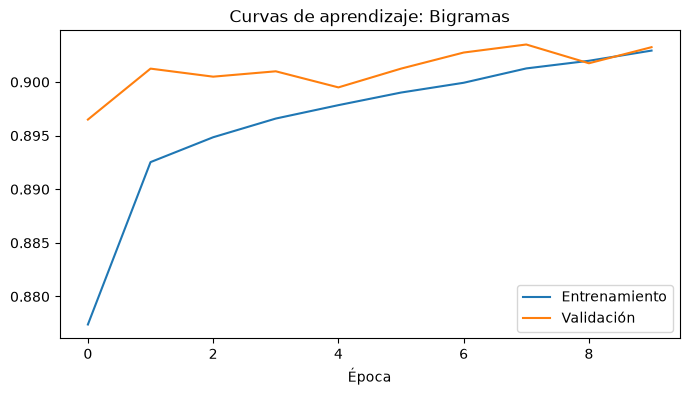

Bigramas + densa {'tipo': 'conjunto', 'parametros': 480033, 'exhaustividad': 0.925, 'precision': 0.886, 'exactitud': 0.903, 'cumple': True}


In [11]:
def entrenar(nombre, modelo, ds_train, ds_val, perdida="binary_crossentropy"):
    modelo.compile(optimizer="rmsprop", loss=perdida, metrics=["accuracy"])
    parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    inicio = time.time()
    historia = modelo.fit(ds_train, validation_data=ds_val, epochs=10, callbacks=[parar], verbose=2)
    segundos = time.time() - inicio
    print(f"Tiempo de entrenamiento: {segundos / 60:.1f} min")

    plt.figure(figsize=(8, 4))
    plt.plot(historia.history["accuracy"], label="Entrenamiento")
    plt.plot(historia.history["val_accuracy"], label="Validación")
    plt.title(f"Curvas de aprendizaje: {nombre}")
    plt.xlabel("Época")
    plt.legend()
    plt.show()
    return segundos


def prob_keras(modelo, vectorizador, textos, cinco_estrellas=False):
    ds = tf.data.Dataset.from_tensor_slices(textos).batch(256).map(vectorizador)
    p = modelo.predict(ds, verbose=0)
    if cinco_estrellas:
        return p[:, 0] + p[:, 1]   # P(1 estrella) + P(2 estrellas)
    return p[:, 0]


vec_bi = layers.TextVectorization(max_tokens=30_000, output_mode="multi_hot", ngrams=2)
vec_bi.adapt(textos_train)
train_bi, val_bi = vectorizar(train_ds, vec_bi), vectorizar(val_ds, vec_bi)

keras.utils.set_random_seed(SEED)
entradas = keras.Input(shape=(vec_bi.vocabulary_size(),))
x = layers.Dense(16, activation="relu")(entradas)
x = layers.Dropout(0.5)(x)
salidas = layers.Dense(1, activation="sigmoid")(x)
modelo_bi = keras.Model(entradas, salidas)

seg = entrenar("Bigramas", modelo_bi, train_bi, val_bi)
registrar("Bigramas + densa", "conjunto", modelo_bi.count_params(), lambda t: prob_keras(modelo_bi, vec_bi, t), seg)

## 5. Modelo 2: Embedding + Bi-LSTM
También sale de nuestro cuaderno de embeddings: secuencias de 128 tokens, un Embedding de 64 y una LSTM bidireccional de 32. Este sí ve el orden de las palabras, por ejemplo "no me gustó" contra "me gustó".

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 64)       │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,944,897 (7.42 MB)

 Trainable params: 1,944,897 (7.42 MB)

 Non-trainable params: 0 (0.00 B)

C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (12 outputs left out)

5000/5000 - 56s - 11ms/step - accuracy: 0.9442 - loss: 0.1625 - val_accuracy: 0.9140 - val_loss: 0.2225


Epoch 7/10


5000/5000 - 56s - 11ms/step - accuracy: 0.9485 - loss: 0.1516 - val_accuracy: 0.9128 - val_loss: 0.2330


Tiempo de entrenamiento: 6.5 min


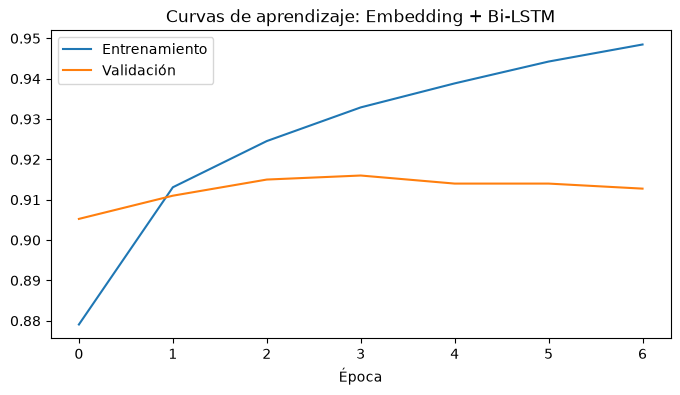

Embedding + Bi-LSTM {'tipo': 'recurrente', 'parametros': 1944897, 'exhaustividad': 0.944, 'precision': 0.894, 'exactitud': 0.916, 'cumple': True}


In [12]:
vec_seq = layers.TextVectorization(max_tokens=30_000, output_mode="int", output_sequence_length=128)
vec_seq.adapt(textos_train)
train_seq, val_seq = vectorizar(train_ds, vec_seq, cache=True), vectorizar(val_ds, vec_seq, cache=True)

keras.utils.set_random_seed(SEED)
entradas = keras.Input(shape=(None,), dtype="int64")
x = layers.Embedding(vec_seq.vocabulary_size(), 64)(entradas)
x = layers.Bidirectional(layers.LSTM(32))(x)
x = layers.Dropout(0.5)(x)
salidas = layers.Dense(1, activation="sigmoid")(x)
modelo_seq = keras.Model(entradas, salidas)
modelo_seq.summary()

seg = entrenar("Embedding + Bi-LSTM", modelo_seq, train_seq, val_seq)
registrar("Embedding + Bi-LSTM", "recurrente", modelo_seq.count_params(), lambda t: prob_keras(modelo_seq, vec_seq, t), seg)

## 6. Modelo 3: BETO ajustado
BETO es un BERT entrenado en español. Le ponemos una capa nueva con 2 salidas (positiva y negativa) y lo ajustamos completo con el `Trainer`, como en nuestro cuaderno de transformers: learning rate de 3e-5 y lotes de 16.

Con las 160,000 reseñas tardaría horas, así que lo entrenamos con una **muestra de 20,000** y solo **2 épocas**. La validación sí es la completa.

In [13]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding
from transformers import Trainer, TrainingArguments

NOMBRE_BETO = "dccuchile/bert-base-spanish-wwm-cased"
id2label = {0: "positiva", 1: "negativa"}
label2id = {v: k for k, v in id2label.items()}
tokenizador = AutoTokenizer.from_pretrained(NOMBRE_BETO)
beto = AutoModelForSequenceClassification.from_pretrained(NOMBRE_BETO, revision="refs/pr/3", num_labels=2,
                                                          id2label=id2label, label2id=label2id)


class DatasetResenas(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.codificados = tokenizador(list(textos), truncation=True, max_length=128)
        self.etiquetas = list(etiquetas)
    def __len__(self):
        return len(self.etiquetas)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.codificados.items()}
        item["labels"] = int(self.etiquetas[i])
        return item


muestra = train_b.sample(20_000, random_state=SEED)
x_muestra, y_muestra = muestra["text"].values, (muestra["estrellas"] <= 2).astype(int).values
print(f"Muestra para BETO: {len(x_muestra):,} reseñas ({y_muestra.mean() * 100:.0f} % negativas)")

ds_train_beto, ds_val_beto = DatasetResenas(x_muestra, y_muestra), DatasetResenas(x_val, y_val)

W1107 11:58:07.583000 45664 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Muestra para BETO: 20,000 reseñas (51 % negativas)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.237993,0.236050,0.923750
2,0.120960,0.249672,0.927250


Tiempo de entrenamiento: 6.1 min


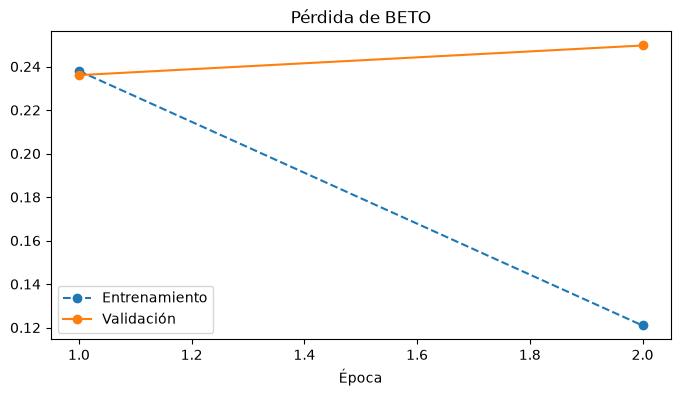

BETO ajustado {'tipo': 'transformer', 'parametros': 109852418, 'exhaustividad': 0.929, 'precision': 0.926, 'exactitud': 0.927, 'cumple': True}


In [14]:
def calcular_metricas(eval_pred):
    logits, etiquetas = eval_pred
    return {"accuracy": accuracy_score(etiquetas, logits.argmax(axis=-1))}

args = TrainingArguments(output_dir="beto_tmp", num_train_epochs=2, learning_rate=3e-5,
                         per_device_train_batch_size=16, per_device_eval_batch_size=64, weight_decay=0.01,
                         eval_strategy="epoch", save_strategy="no", logging_strategy="epoch",
                         fp16=GPU and torch.cuda.get_device_capability()[0] >= 7, report_to="none", seed=SEED)
trainer = Trainer(model=beto, args=args, train_dataset=ds_train_beto, eval_dataset=ds_val_beto,
                  data_collator=DataCollatorWithPadding(tokenizador), compute_metrics=calcular_metricas)
inicio = time.time()
trainer.train()
seg_beto = time.time() - inicio
print(f"Tiempo de entrenamiento: {seg_beto / 60:.1f} min")

hist = pd.DataFrame(trainer.state.log_history)
plt.figure(figsize=(8, 4))
plt.plot(hist.dropna(subset=["loss"])["epoch"], hist.dropna(subset=["loss"])["loss"], "o--", label="Entrenamiento")
plt.plot(hist.dropna(subset=["eval_loss"])["epoch"], hist.dropna(subset=["eval_loss"])["eval_loss"], "o-", label="Validación")
plt.title("Pérdida de BETO")
plt.xlabel("Época")
plt.legend()
plt.show()


def prob_beto(textos):
    logits = trainer.predict(DatasetResenas(textos, np.zeros(len(textos)))).predictions
    return torch.softmax(torch.tensor(logits), dim=-1)[:, 1].numpy()   # probabilidad de negativa

parametros_beto = sum(p.numel() for p in beto.parameters() if p.requires_grad)
registrar("BETO ajustado", "transformer", parametros_beto, prob_beto, seg_beto)

## 7. Extra: Bi-LSTM con las 5 estrellas
La idea es ver si al modelo le sirve aprender la calificación completa (1 a 5) en vez de solo negativa o positiva, porque así distingue una queja fuerte (1) de una tibia (2).
- Aquí **sí usamos las de 3 estrellas**, porque son una clase más.
- Es la misma Bi-LSTM, con salida `softmax` de 5 y `sparse_categorical_crossentropy`, como en nuestro cuaderno de embeddings.
- Para el cliente: **probabilidad de negativa = P(1 estrella) + P(2 estrellas)**, y se marca si pasa de 0.5.
- Este modelo también es el que recomienda las estrellas en la app de Gradio.

C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10


C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\backend\torch\rnn.py:1076: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  outputs, h_n, c_n = torch._VF.lstm(


6250/6250 - 72s - 12ms/step - accuracy: 0.4874 - loss: 1.1633 - val_accuracy: 0.5118 - val_loss: 1.0849


Epoch 2/10


6250/6250 - 69s - 11ms/step - accuracy: 0.5330 - loss: 1.0714 - val_accuracy: 0.5248 - val_loss: 1.0620


... (7 outputs left out)

6250/6250 - 69s - 11ms/step - accuracy: 0.5952 - loss: 0.9628 - val_accuracy: 0.5404 - val_loss: 1.0568


Epoch 7/10


6250/6250 - 70s - 11ms/step - accuracy: 0.6099 - loss: 0.9386 - val_accuracy: 0.5358 - val_loss: 1.0805


Tiempo de entrenamiento: 8.2 min


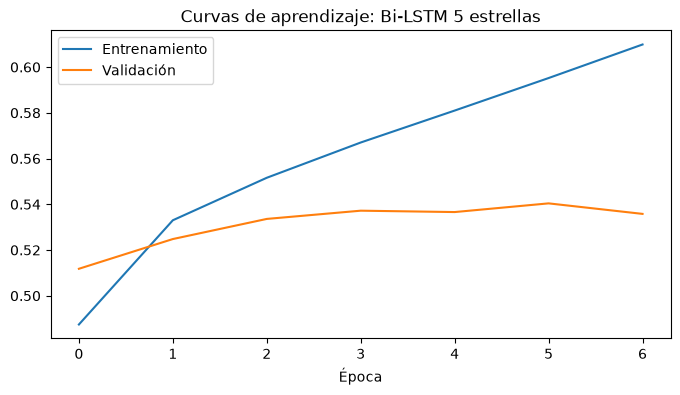

Bi-LSTM 5 estrellas (extra) {'tipo': 'recurrente', 'parametros': 1945157, 'exhaustividad': 0.851, 'precision': 0.944, 'exactitud': 0.9, 'cumple': False}


In [15]:
train5_ds = a_dataset(train["text"].values, train["label"].values, mezclar=True)
val5_ds = a_dataset(val["text"].values, val["label"].values)
train5, val5 = vectorizar(train5_ds, vec_seq, cache=True), vectorizar(val5_ds, vec_seq, cache=True)   # mismo vocabulario de antes

keras.utils.set_random_seed(SEED)
entradas = keras.Input(shape=(None,), dtype="int64")
x = layers.Embedding(vec_seq.vocabulary_size(), 64)(entradas)
x = layers.Bidirectional(layers.LSTM(32))(x)
x = layers.Dropout(0.5)(x)
salidas = layers.Dense(5, activation="softmax")(x)
modelo_5 = keras.Model(entradas, salidas)

seg = entrenar("Bi-LSTM 5 estrellas", modelo_5, train5, val5, perdida="sparse_categorical_crossentropy")
registrar("Bi-LSTM 5 estrellas (extra)", "recurrente", modelo_5.count_params(),
          lambda t: prob_keras(modelo_5, vec_seq, t, cinco_estrellas=True), seg)

In [16]:
# ¿Qué tan bien recomienda las estrellas? (validación completa, con las de 3)
p5 = modelo_5.predict(val5, verbose=0)
estrella_pred = p5.argmax(axis=1) + 1
distancia = np.abs(estrella_pred - val["estrellas"].values)
print(f"Le atina exacto a la estrella: {np.mean(distancia == 0) * 100:.1f} %")
print(f"Se equivoca por 1 estrella:    {np.mean(distancia == 1) * 100:.1f} %")
print(f"Se equivoca por 2 o más:       {np.mean(distancia >= 2) * 100:.1f} %")

C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\backend\torch\rnn.py:1076: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  outputs, h_n, c_n = torch._VF.lstm(


Le atina exacto a la estrella: 53.7 %
Se equivoca por 1 estrella:    38.3 %
Se equivoca por 2 o más:       7.9 %


**¿Agarró más contexto?** No. En validación, el de 5 estrellas tiene la precisión más alta (94 %), pero su exhaustividad baja a 85 %, así que **no cumple**.
Nuestra explicación: ahora existe una clase de en medio (3 estrellas), y muchas negativas "tibias" de 2 estrellas se le van a 3. Al sumar P(1) + P(2) ya no llegan a 0.5.

Para el cliente nos quedamos con los modelos binarios. Para **recomendar estrellas** sí sirve: le atina exacto el 54 % de las veces, el 38 % se equivoca por solo 1 estrella y nada más el 8 % se equivoca por 2 o más. Por eso este es el que usamos en la app de Gradio.

## 8. Elección con validación
El cliente recibe miles de reseñas al día, así que no solo importa que el modelo atine. También importa cuánto cuesta tenerlo funcionando. Por eso comparamos cuatro cosas, todas en validación:
- **Calidad:** exhaustividad, precisión y exactitud.
- **Margen:** cuántos puntos queda arriba de lo que pide el cliente (90 % y 85 %). Con más margen es más seguro que también cumpla en la prueba.
- **Tiempo:** cuánto tarda en entrenar y cuánto en clasificar las 4,000 reseñas de validación.
- **Peso:** cuánto ocupan sus pesos (parámetros × 4 bytes), que dice cuánta memoria necesita y si cabe en GitHub (menos de 100 MB).

Nuestra regla: **de los que cumplen las dos especificaciones, nos quedamos con el que tiene menos parámetros**, porque es el más ligero y el más sencillo. Si ninguno cumpliera, nos quedaríamos con el de mayor exactitud.

In [17]:
tabla_val = pd.DataFrame(validacion).T
comparacion = tabla_val[["exhaustividad", "precision", "exactitud", "cumple", "parametros"]].copy()
comparacion["margen exhaustividad (pts)"] = ((comparacion["exhaustividad"] - 0.90) * 100).astype(float).round(1)
comparacion["margen precisión (pts)"] = ((comparacion["precision"] - 0.85) * 100).astype(float).round(1)
comparacion = comparacion.join(pd.DataFrame(costos).T)
comparacion["¿cabe en GitHub?"] = comparacion["peso (MB aprox.)"] < 100
comparacion

,exhaustividad,precision,exactitud,cumple,parametros,margen exhaustividad (pts),margen precisión (pts),entrenar (min),"clasificar 4,000 reseñas (s)",peso (MB aprox.),¿cabe en GitHub?
Línea base (todo negativa),1.0,0.5,0.5,False,0,10.0,-35.0,0.0,0.0,0.0,True
Bigramas + densa,0.9255,0.886494,0.9035,True,480033,2.5,3.6,12.4,0.9,1.9,True
Embedding + Bi-LSTM,0.9435,0.894313,0.916,True,1944897,4.3,4.4,6.5,0.2,7.8,True
BETO ajustado,0.929,0.92576,0.92725,True,109852418,2.9,7.6,6.1,10.6,439.4,False
Bi-LSTM 5 estrellas (extra),0.8505,0.943951,0.9,False,1945157,-4.9,9.4,8.2,0.2,7.8,True


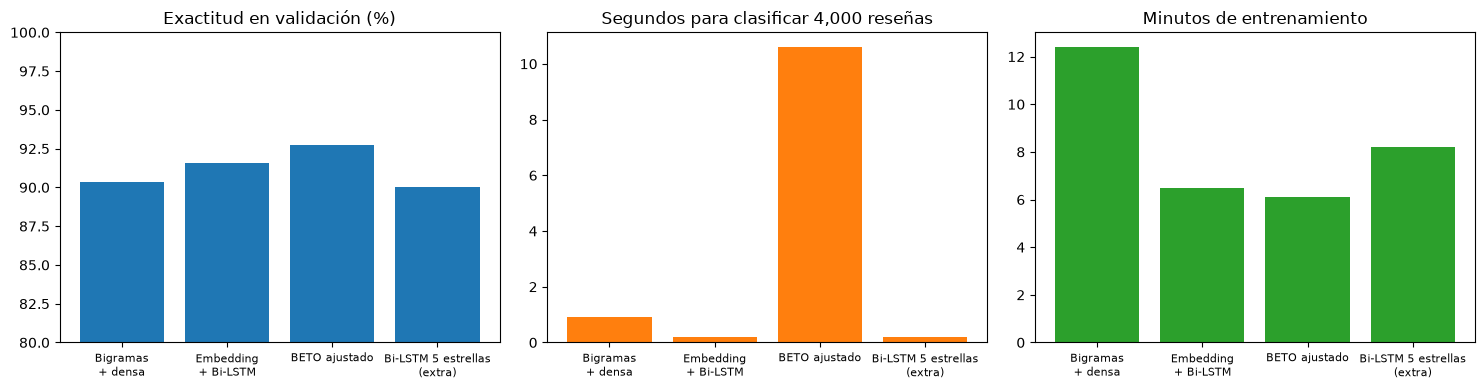

In [18]:
# Gráfica: calidad contra tiempo (sin la línea base)
sin_base = comparacion.drop(index="Línea base (todo negativa)")
nombres = [n.replace(" (extra)", "\n(extra)").replace(" + ", "\n+ ") for n in sin_base.index]

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].bar(nombres, sin_base["exactitud"].astype(float) * 100, color="tab:blue")
ejes[0].set_ylim(80, 100)
ejes[0].set_title("Exactitud en validación (%)")
ejes[1].bar(nombres, sin_base["clasificar 4,000 reseñas (s)"].astype(float), color="tab:orange")
ejes[1].set_title("Segundos para clasificar 4,000 reseñas")
ejes[2].bar(nombres, sin_base["entrenar (min)"].astype(float), color="tab:green")
ejes[2].set_title("Minutos de entrenamiento")
for eje in ejes:
    eje.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

In [19]:
cumplen = tabla_val[tabla_val["cumple"] == True]
if len(cumplen) > 0:
    elegido = cumplen["parametros"].astype(int).idxmin()
else:
    elegido = tabla_val["exactitud"].astype(float).idxmax()
print("Modelo elegido:", elegido)

Modelo elegido: Bigramas + densa


**Lo que vemos en la comparación:**
- **Calidad:** los tres cumplen. BETO tiene la mejor precisión (92.6 %) y la Bi-LSTM la mejor exhaustividad (94.4 %). Los Bigramas son los que menos margen tienen: 2.5 puntos arriba en exhaustividad y 3.6 en precisión.
- **Tiempo de entrenamiento:** nos sorprendió que los Bigramas tardaran más (12.4 min) que la Bi-LSTM (6.5 min). Usaron las 10 épocas y cada reseña se convierte en un vector de 30,000. BETO tardó 6.1 min, pero solo con 20,000 reseñas, 8 veces menos datos. Con las 160,000 serían unos 50 min.
- **Tiempo para clasificar 4,000 reseñas:** Bi-LSTM 0.2 s, Bigramas 0.9 s y BETO 10.6 s. BETO es unas 50 veces más lento que la Bi-LSTM. Los dos modelos de Keras tardan menos de un segundo, así que para miles de reseñas al día cualquiera de los dos alcanza.
- **Peso:** Bigramas 1.9 MB, Bi-LSTM 7.8 MB y BETO 439 MB, que no cabe en GitHub.

**En resumen:** los Bigramas ganan en peso y en sencillez, pero la Bi-LSTM les gana en calidad y en velocidad para clasificar. Según nuestra regla nos quedamos con los Bigramas, sabiendo que la Bi-LSTM sería la siguiente opción.

## 9. Prueba del cliente (una sola vez)
Ahora sí usamos la prueba, con todos los modelos de una vez y sin cambiar nada después.

In [20]:
filas, probs_prueba = [], {}
for nombre, m in modelos.items():
    probs_prueba[nombre] = m["predecir"](X_prueba)
    filas.append({"modelo": nombre, "tipo": m["tipo"], "parametros": m["parametros"],
                  **metricas(y_prueba, probs_prueba[nombre]), "elegido": nombre == elegido})

resultados = pd.DataFrame(filas)
resultados = resultados[["modelo", "tipo", "parametros", "exhaustividad", "precision", "exactitud", "cumple", "elegido"]]
resultados.to_csv("resultados_resenas.csv", index=False)
resultados.round(3)

C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\backend\torch\rnn.py:1076: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  outputs, h_n, c_n = torch._VF.lstm(


C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\backend\torch\rnn.py:1076: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  outputs, h_n, c_n = torch._VF.lstm(


,modelo,tipo,parametros,exhaustividad,precision,exactitud,cumple,elegido
0,Línea base (todo negativa),linea base,0,1.000,0.500,0.500,False,False
1,Bigramas + densa,conjunto,480033,0.924,0.897,0.908,True,True
2,Embedding + Bi-LSTM,recurrente,1944897,0.944,0.905,0.923,True,False
3,BETO ajustado,transformer,109852418,0.932,0.940,0.936,True,False
4,Bi-LSTM 5 estrellas (extra),recurrente,1945157,0.856,0.949,0.905,False,False


In [21]:
fila = resultados[resultados["elegido"]].iloc[0]
print(f"Modelo elegido: {fila['modelo']}")
print(f"De cada 100 reseñas negativas, marca {fila['exhaustividad'] * 100:.0f}  (pide 90 o más)")
print(f"De cada 100 que marca como negativas, {fila['precision'] * 100:.0f} sí lo son  (pide 85 o más)")
print("Cumple las especificaciones:", "sí" if fila["cumple"] else "no")

Modelo elegido: Bigramas + densa
De cada 100 reseñas negativas, marca 92  (pide 90 o más)
De cada 100 que marca como negativas, 90 sí lo son  (pide 85 o más)
Cumple las especificaciones: sí


## 10. Justificación
En validación cumplieron tres modelos:

| Modelo | Exhaustividad | Precisión | Clasificar 4,000 | Peso |
|---|---|---|---|---|
| Bigramas + densa | 92.5 % | 88.6 % | 0.9 s | 1.9 MB |
| Embedding + Bi-LSTM | 94.4 % | 89.4 % | 0.2 s | 7.8 MB |
| BETO ajustado | 93.0 % | 92.6 % | 10.6 s | 439 MB |

Con nuestra regla nos quedamos con los **Bigramas**. Cumplen lo que pide el cliente, son el modelo más ligero (230 veces menos parámetros que BETO) y el más fácil de explicar: buscan qué palabras y pares de palabras trae la reseña.

En la prueba lo confirma: **de cada 100 reseñas negativas marca 92, y de cada 100 que marca como negativas, 90 sí lo son.**

Siendo honestos:
- La Bi-LSTM le gana a los Bigramas en calidad (92.3 % contra 90.8 % de exactitud en la prueba) y en velocidad para clasificar, y sigue siendo ligera (7.8 MB). Si el cliente necesita más margen, es la siguiente opción.
- BETO es el mejor en precisión y exactitud (93.6 % en la prueba), pero pesa 439 MB y es unas 50 veces más lento para clasificar.
- El margen de los Bigramas en exhaustividad es chico: 92.4 % contra el 90 % que se pide.
- Hay 45 reseñas de la prueba que también vienen en el entrenamiento (así viene el dataset). Son el 1 % de la prueba. No las quitamos porque la prueba es la del cliente y no se cambia, pero pueden subir un poquito los números.

## 11. Errores del modelo elegido

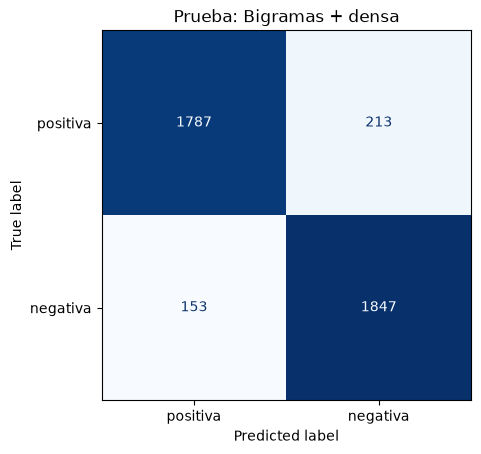

Errores: 366 de 4,000
Negativas que no marcó: 153 · Positivas que marcó como negativas: 213
Errores por estrellas:
estrellas
1     27
2    126
4    149
5     64
Name: count, dtype: int64


In [22]:
pred_e = (probs_prueba[elegido] >= UMBRAL).astype(int)
ConfusionMatrixDisplay.from_predictions(y_prueba, pred_e, display_labels=["positiva", "negativa"], cmap="Blues", colorbar=False)
plt.title(f"Prueba: {elegido}")
plt.show()

errores = pd.DataFrame({"reseña": X_prueba, "estrellas": prueba["estrellas"].values,
                        "real": y_prueba, "P(negativa)": probs_prueba[elegido].round(3), "pred": pred_e})
errores = errores[errores["real"] != errores["pred"]]
print(f"Errores: {len(errores)} de {len(X_prueba):,}")
print(f"Negativas que no marcó: {(errores['real'] == 1).sum()} · Positivas que marcó como negativas: {(errores['real'] == 0).sum()}")
print("Errores por estrellas:")
print(errores["estrellas"].value_counts().sort_index())

In [23]:
# los errores donde el modelo estaba más seguro
no_marco = errores[errores["real"] == 1].sort_values("P(negativa)").head(5)
falsa_alarma = errores[errores["real"] == 0].sort_values("P(negativa)", ascending=False).head(5)
pd.concat([no_marco, falsa_alarma])

,reseña,estrellas,real,P(negativa),pred
1255,"La calidad del producto no es muy buena pero me pareció un precio bastante barato y lo compré, en la práctica cumple su función y es justo lo que necesitaba, el unico problema es que venía con alg...",2,1,0.000,0
1278,"Los cascos en si están bien , se conectan a mí Xbox One X perfectamente y se escuchan muy bien , pero , el volumen máximo es insuficiente , siempre es mejor que sobre volumen y que la persona lo r...",2,1,0.000,0
1620,"Papel resistente. Portadas de tacto suave pero mancha con facilidad, se queda marcado el roce desde el minuto uno, por lo que en un día a día la portada se queda con los dedos marcados. No tiene c...",2,1,0.000,0
1089,"la verdad que a recibirlo y verlo de primera me gusto mucho de vista ,ahora a la hora de usarlo es un poco corto en comparación con samsung que suelo usar yo . para una persona que no le va a dar ...",2,1,0.001,0
1821,El tensiómetro está muy bien. Es muy cómodo porque no tiene el tubito que es un poco molesto y puede partirse con el tiempo. PERO... La ventana de la lectura me parece muy pequeña en comparación c...,2,1,0.001,0
2182,"Estaba harto de usar encendedores de gas porque duran muy poco, no se pueden recargar y cuando les queda poco les cuesta encender. Este con solo pulsar el botón te enciende el fogón en un instante...",4,0,0.998,1
2939,"El producto en sí bien porque ya tenía otro y se de qué va el tema, pero muy mal el embalaje. Inexistente. Sin caja de Amazon, tan sólo la caja de propio producto y sin precintar no nada. No es no...",4,0,0.998,1
2356,"Despues de esperar mas de dos meses porque estaba sin stock! El paquete ha llegado muy deteriorado, adjunto fotos! Aun no hemos entregado el regalo, esperemos que funcione correctamente!",4,0,0.997,1
2591,"Imagen en 4K y 3D perfecta. Pero compré un disco duro interno de 3Tb y no lo lee. Al final, tuve que devolver el disco duro interno y con uno externo va perfecto. Como multimedia es excelente. Es ...",4,0,0.990,1
3674,Magnifica compra estas bolsas los armarios los he dejado vacíos ya que estaba lleno de ropa e increíblemente ha cabido todo en tres bolsas de las grandes viene con un aparato para sacar el aire pe...,5,0,0.987,1


**Análisis de 3 errores**

De 4,000 reseñas falla en 366. Hay 153 negativas que no marcó (126 son de 2 estrellas) y 213 falsas alarmas (149 son de 4 estrellas). Casi todos los errores están en las reseñas "tibias", de 2 y 4 estrellas, que mezclan cosas buenas y malas.

1. **Negativa que no marcó (#1278, 2 estrellas, P = 0.000):** "Los cascos en sí están bien, se conectan perfectamente y se escuchan muy bien, pero el volumen máximo es insuficiente...". Empieza con puros elogios. Los bigramas cuentan las palabras buenas y no entienden que lo que viene después del "pero" es lo que pesa.
2. **Falsa alarma (#2939, 4 estrellas, P = 0.998):** "El producto en sí bien... pero muy mal el embalaje. Inexistente." La queja es del envío, no del producto, y aun así puso 4 estrellas. Para el modelo "muy mal" pesa muchísimo. Para el cliente esta falsa alarma no es tan grave, porque la persona sí estaba molesta por algo.
3. **Falsa alarma (#3674, 5 estrellas, P = 0.987):** "Magnífica compra... no tiene mucha fuerza... para el que tenga problemas de espacio lo aconsejo". Es una reseña larga, sin puntos, que usa palabras como "problemas", "vacíos" o "no tiene fuerza" para decir algo bueno. Como los bigramas no ven el orden, se van con esas palabras sueltas.

**Conclusión:** los Bigramas fallan cuando la reseña mezcla lo bueno y lo malo, porque no ven el orden. La Bi-LSTM y BETO sí lo ven y por eso se equivocan menos (92.3 % y 93.6 % de exactitud en la prueba). Esa sería la propuesta de mejora si el cliente necesita más margen.

## 12. Guardar los modelos
- `modelo/modelo_resenas.keras`: el modelo elegido (o la carpeta `modelo/beto/` si el elegido es BETO).
- `modelo/modelo_estrellas.keras`: el extra de 5 estrellas, que usa la app de Gradio.
- `modelo/vocabulario.json`: el vocabulario de las secuencias, para que la app convierta el texto igual que aquí.

In [24]:
os.makedirs("modelo", exist_ok=True)

if elegido == "BETO ajustado":
    trainer.save_model("modelo/beto")
    tokenizador.save_pretrained("modelo/beto")
elif elegido == "Bigramas + densa":
    modelo_bi.save("modelo/modelo_resenas.keras")
    json.dump(vec_bi.get_vocabulary(), open("modelo/vocabulario_bigramas.json", "w", encoding="utf-8"))
elif elegido == "Embedding + Bi-LSTM":
    modelo_seq.save("modelo/modelo_resenas.keras")

modelo_5.save("modelo/modelo_estrellas.keras")
json.dump(vec_seq.get_vocabulary(), open("modelo/vocabulario.json", "w", encoding="utf-8"))
print(os.listdir("modelo"))

['beto', 'modelo_estrellas.keras', 'modelo_resenas.keras', 'vocabulario.json', 'vocabulario_bigramas.json']


## 13. Extra: probarlo con Gradio
Escribimos una reseña y nos dice dos cosas:
- **Si es negativa**, con el modelo elegido (Bigramas).
- **Cuántas estrellas le recomienda**, con el Bi-LSTM de 5 estrellas del extra.

In [25]:
import gradio as gr


def analizar(resena):
    if not resena.strip():
        return "Escribe una reseña.", {}
    p_negativa = float(prob_keras(modelo_bi, vec_bi, np.array([resena]))[0])
    ds = tf.data.Dataset.from_tensor_slices(np.array([resena])).batch(1).map(vec_seq)   # igual que en prob_keras
    p_estrellas = modelo_5.predict(ds, verbose=0)[0]
    estrellas = int(p_estrellas.argmax()) + 1

    if p_negativa >= UMBRAL:
        texto = f"### 🔴 Reseña NEGATIVA: atender primero\nProbabilidad de negativa: **{p_negativa:.0%}**"
    else:
        texto = f"### 🟢 Reseña no negativa\nProbabilidad de negativa: **{p_negativa:.0%}**"
    texto += f"\n\n**Calificación recomendada:** {'★' * estrellas}{'☆' * (5 - estrellas)} ({estrellas} de 5)"
    return texto, {f"{i + 1} estrellas": float(p) for i, p in enumerate(p_estrellas)}


# lo probamos antes de abrir la interfaz
for ejemplo in ["Llegó roto y el vendedor no contesta. No lo vuelvo a comprar.",
                "Muy buena calidad, llegó antes de lo esperado. Lo recomiendo.",
                "Está bien por el precio, aunque la batería dura poco."]:
    print(ejemplo, "->", analizar(ejemplo)[0].replace("\n", " "))

C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\backend\torch\rnn.py:1076: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  outputs, h_n, c_n = torch._VF.lstm(


Llegó roto y el vendedor no contesta. No lo vuelvo a comprar. -> ### 🔴 Reseña NEGATIVA: atender primero Probabilidad de negativa: **98%**  **Calificación recomendada:** ★☆☆☆☆ (1 de 5)
Muy buena calidad, llegó antes de lo esperado. Lo recomiendo. -> ### 🟢 Reseña no negativa Probabilidad de negativa: **0%**  **Calificación recomendada:** ★★★★★ (5 de 5)


Está bien por el precio, aunque la batería dura poco. -> ### 🟢 Reseña no negativa Probabilidad de negativa: **36%**  **Calificación recomendada:** ★★★★☆ (4 de 5)


In [26]:
with gr.Blocks(title="Detector de reseñas negativas") as demo:
    gr.Markdown("## Detector de reseñas negativas")
    resena = gr.Textbox(label="Reseña del cliente", lines=4, placeholder="Escribe o pega una reseña...")
    boton = gr.Button("Analizar", variant="primary")
    with gr.Row():
        salida = gr.Markdown()
        grafica = gr.Label(label="Probabilidad de cada calificación", num_top_classes=5)
    boton.click(analizar, resena, [salida, grafica])
    resena.submit(analizar, resena, [salida, grafica])

demo.launch(prevent_thread_lock=True, inline=False)

* Running on local URL:  http://127.0.0.1:7860


* To create a public link, set `share=True` in `launch()`.


## 14. Conclusión: lo que nosotros usaríamos

**Si tuviéramos que poner esto a funcionar, empezaríamos con los Bigramas.** Cumplen lo que pide el cliente (de cada 100 negativas marcan 92, y de cada 100 que marcan, 90 sí lo son), son el modelo más ligero (1.9 MB) y el más fácil de explicar.

**Si vemos que hace falta subir de nivel, nos pasaríamos a la Bi-LSTM.** Por ejemplo, si el cliente pide más margen o si empiezan a fallar las reseñas que mezclan cosas buenas y malas. La Bi-LSTM es un poco más precisa (92.3 % contra 90.8 % de exactitud en la prueba) y tiene más margen, a cambio de pesar más (7.8 MB).

**Antes de cambiar tendríamos en cuenta lo que cuesta reentrenar cada uno**, porque el modelo se va a tener que reentrenar:

| | Bigramas | Bi-LSTM |
|---|---|---|
| Reentrenar con 160,000 reseñas (con nuestra GPU) | 12.4 min | 6.5 min |
| Clasificar 4,000 reseñas | 0.9 s | 0.2 s |
| Peso | 1.9 MB | 7.8 MB |
| Exactitud en la prueba | 90.8 % | 92.3 % |

**Limitación importante: este modelo sirve para el tono de España.** Lo entrenamos con reseñas de Amazon España ("vale", "móvil", "os podéis imaginar"). Compra Fácil Bajío es mexicana y sus clientes escriben distinto ("está chido", "celular", "no sirve"). Además, las palabras que el modelo no vio al entrenar las toma como desconocidas. Por eso lo más probable es que **la precisión y la exhaustividad bajen con reseñas mexicanas**. No lo medimos porque no tenemos reseñas mexicanas, así que antes de usarlo habría que reentrenarlo con reseñas de la propia tienda. Eso es fácil, porque cada reseña ya trae sus estrellas como etiqueta.